# g-distance: accommodation and excess flexibility

*The vignette `vignette("gdistance")` of the R package clobe, ported to `psp.clobe`.*

A common way to evaluate a model is to fit it to the average result and see how close it gets. But people differ, and a model of human behaviour should be able to do what each of them does, without doing much that none of them do. g-distance (Dome & Wills, 2025) measures exactly that. This notebook defines it step by step, works through an example by hand, and shows how to read the result.

In [1]:
import math

import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from psp import clobe

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.spines.bottom": False, "axes.grid": True, "grid.color": "#e9ecef", "axes.axisbelow": True,
    "axes.labelcolor": "#495057", "xtick.color": "#495057", "ytick.color": "#495057",
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False, "legend.fontsize": 11,
})

## Three sets of patterns

Everything is expressed in terms of ordinal patterns (inequality matrices; see [inequality-matrices.ipynb](inequality-matrices.ipynb)). We need three sets:

- $H$: the distinct patterns that **h**umans produced, with $f_h$ the proportion of people who produced pattern $h$ (so the $f_h$ add up to 1).
- $M$: the distinct patterns the **m**odel produces somewhere in its parameter space.
- $U$: the **u**niversal set, every pattern that could possibly be observed (see [universal-set.ipynb](universal-set.ipynb)).

$H$ and $M$ are both parts of $U$. Each set counts a pattern once, however often it occurs.

## Accommodation: alpha

**Accommodation** is the proportion of people whose pattern the model can produce:

$$
\alpha = \sum_{h \in H} f_h \times
\begin{cases} 1 & \text{if } h \in M \\ 0 & \text{otherwise.} \end{cases}
$$

It runs from 0 (the model produces nobody's pattern) to 1 (it produces everybody's). Because it is weighted by $f_h$, missing a pattern that many people show costs more than missing a rare one.

## Excess flexibility: beta

A model that produces every possible pattern accommodates everyone, but it explains nothing. **Excess flexibility** is the proportion of the patterns that *nobody* produced that the model produces anyway:

$$
\beta = \frac{|M \setminus H|}{|U| - |H|},
$$

where $|M \setminus H|$ is the number of model patterns not observed in humans, and $|U| - |H|$ is the number of possible patterns not observed in humans. It runs from 0 (the model predicts nothing beyond what was observed) to 1 (it predicts every unobserved pattern).

## Combining them: g-distance

The ideal model has $\alpha = 1$ and $\beta = 0$: it produces every observed pattern and nothing else. g-distance is how far a model is from that ideal:

$$
g = \sqrt{\, w (1 - \alpha)^2 + (1 - w) \beta^2 \,}.
$$

This is the ordinary (Pythagorean) distance between the point $(1 - \alpha, \beta)$ and the ideal point $(0, 0)$, with the two directions weighted by $w$ and $1 - w$. It runs from 0 (ideal) to 1. Lower is better.

The **weight** $w$ says how much you care about missing human behaviour compared with producing behaviour nobody showed. With $w = 0.5$, both count equally. A larger $w$ penalises missed participants more; a smaller $w$ penalises flexibility more.

## A worked example

Three stimuli, four participants. Two produce the same pattern (A), and one each produces B and C. The model produces A and B, and two patterns nobody showed (D and E).

In [2]:
thresholds = (0.1, -0.1)
people = torch.tensor([[0.9, 0.5, 0.1],   # A: 0 > 1 > 2
                       [0.8, 0.5, 0.2],   # A again
                       [0.1, 0.5, 0.9],   # B: 0 < 1 < 2
                       [0.5, 0.5, 0.5]])  # C: all about the same
model = torch.tensor([[0.9, 0.5, 0.1],    # A
                      [0.1, 0.5, 0.9],    # B
                      [0.9, 0.9, 0.1],    # D: 0 = 1 > 2
                      [0.1, 0.9, 0.9]])   # E: 0 < 1 = 2

human = clobe.patterns(people, thresholds)
model = clobe.patterns(model, thresholds)
human.frequencies

tensor([0.5000, 0.2500, 0.2500], dtype=torch.float64)

By hand:

- $\alpha$: A (half of the people) and B (a quarter) are accommodated, C is not: $\alpha = 0.5 + 0.25 = 0.75$.
- $\beta$: there are 19 possible patterns of 3 stimuli (`semiorders(3)`), and people showed 3 of them, leaving 16. The model produces 2 of those 16 (D and E): $\beta = 2 / 16 = 0.125$.
- $g = \sqrt{0.5 \times 0.25^2 + 0.5 \times 0.125^2} \approx 0.198$.

And with `psp.clobe`:

In [3]:
clobe.gdistance(human.inequality_matrices, model.inequality_matrices,
                universal=clobe.semiorders(3), weight=0.5, frequencies=human.frequencies)

GDistanceResult(gdistance=0.19764235376052372, alpha=0.75, beta=0.125, accommodation=tensor([0, 1]))

`accommodation` lists which human patterns (by their index in `human.inequality_matrices`, from 0) the model produces. The R package returns `alpha`, `beta` and `accommodation` only with `xtdo = TRUE`; here they are always there, and `float(result)` is the g-distance.

## Comparing models

Here are three models of the four-stimulus experiment from [getting-started.ipynb](getting-started.ipynb): one that can only produce monotonic changes, one that can also produce U-shapes, and one that produces random probabilities and so can do almost anything.

In [4]:
g = torch.Generator().manual_seed(2025)
x = torch.tensor([-1.5, -0.5, 0.5, 1.5], dtype=torch.float64)
slopes = 0.5 + torch.randn(40, generator=g, dtype=torch.float64)
p = torch.sigmoid(slopes[:, None] * x + 0.3 * torch.randn(40, 4, generator=g, dtype=torch.float64))
human = clobe.patterns(torch.binomial(torch.full_like(p, 20.0), p, generator=g) / 20, thresholds)

grid = torch.arange(-30, 31, dtype=torch.float64) / 10
b, c = (t.reshape(-1, 1) for t in torch.meshgrid(grid, grid, indexing="ij"))
models = {
    "linear": torch.sigmoid(grid[:, None] * x),
    "quadratic": torch.sigmoid(b * x + c * x**2),
    "random": torch.rand(2000, 4, generator=g, dtype=torch.float64),
}


def score(results):
    out = clobe.gdistance(human.inequality_matrices,
                          clobe.patterns(results, thresholds).inequality_matrices,
                          universal=clobe.semiorders(4), weight=0.5, frequencies=human.frequencies)
    return {"alpha": out.alpha, "beta": out.beta, "g": out.gdistance}


scores = pd.DataFrame({name: score(results) for name, results in models.items()}).T
scores.round(3)

,alpha,beta,g
linear,0.225,0.037,0.549
quadratic,0.575,0.385,0.406
random,0.975,0.839,0.593


### Reading a model off the α-β plane

Dome and Wills (2025) plot a model by its excess flexibility $\beta$ against its accommodation $\alpha$, beside three reference models:

- **PAS**, at $\alpha = 1$, $\beta = 0$: produces every pattern people showed and nothing else; $g = 0$.
- **degenerate**, at $\alpha = 1$, $\beta = 1$: produces every pattern in the universal set. It accommodates everyone by predicting everything, and $g = \sqrt{1 - w}$, 0.71 for $w = 0.5$.
- **anti-PAS**, at $\alpha = 0$, $\beta = 1$: produces every pattern nobody showed and none that anybody did; $g = 1$.

The **degenerate level** joins every point as far from the ideal as the degenerate model: $w(1 - \alpha)^2 + (1 - w)\beta^2 = 1 - w$, which for $w = 0.5$ is $\alpha = 1 - \sqrt{1 - \beta^2}$. A model below it is further from the ideal than a model that predicts every possible pattern, and so tells us less about people than predicting nothing in particular. The three models above are shown with their g-distance in brackets.

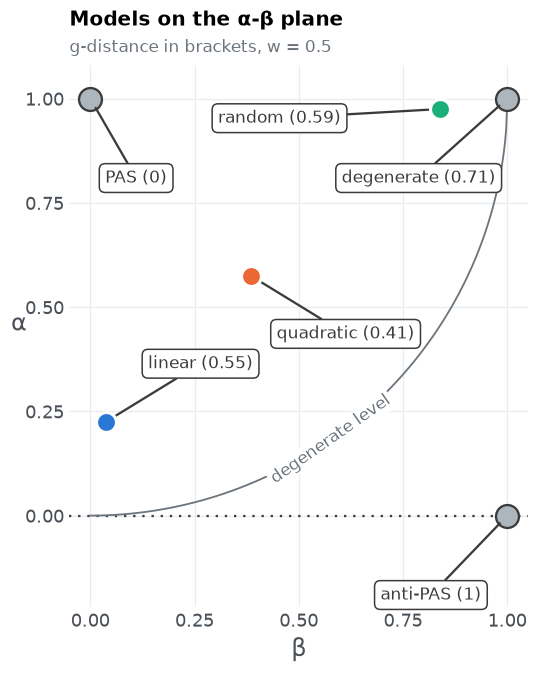

In [5]:
ink, muted, reference = "#3b3b3b", "#6c757d", "#adb5bd"
colours = {"linear": "#2a78d6", "quadratic": "#eb6834", "random": "#1baf7a"}
w = 0.5


def g_of(alpha, beta):
    return math.sqrt(w * (1 - alpha) ** 2 + (1 - w) * beta**2)


def label(ax, text, beta, alpha, offset):
    ax.annotate(text, (beta, alpha), xytext=offset, textcoords="offset points", ha="center",
                va="center", color=ink, fontsize=11,
                bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": ink,
                      "linewidth": 1},
                arrowprops={"arrowstyle": "-", "color": ink, "linewidth": 1.5,
                            "shrinkA": 0, "shrinkB": 7})


fig, ax = plt.subplots(figsize=(6.4, 6.4))
ax.axhline(0, color=ink, linestyle=(0, (1, 3)), linewidth=1.5, zorder=1)

# the degenerate level: w (1 - alpha)^2 + (1 - w) beta^2 = 1 - w
beta = np.linspace(0, 1, 400)
alpha = 1 - np.sqrt((1 - w) * (1 - beta**2) / w)
ax.plot(beta, alpha, color=muted, linewidth=1.2, zorder=1)  # the degenerate model's level
middle = 230
angle = ax.transData.transform_angles(
    np.array([np.degrees(np.arctan2(alpha[middle + 1] - alpha[middle - 1],
                                    beta[middle + 1] - beta[middle - 1]))]),
    np.array([[beta[middle], alpha[middle]]]))[0]
ax.text(beta[middle], alpha[middle], "degenerate level", rotation=angle, rotation_mode="anchor",
        ha="center", va="center", color=muted, fontsize=11, zorder=2,
        bbox={"boxstyle": "square,pad=0.15", "facecolor": "white", "edgecolor": "none"})

for name, (b, a), offset in [("PAS", (0, 1), (30, -52)), ("degenerate", (1, 1), (-58, -52)),
                             ("anti-PAS", (1, 0), (-50, -52))]:
    ax.plot(b, a, "o", color=reference, markersize=15, markeredgecolor=ink, markeredgewidth=1.5,
            zorder=3)
    label(ax, f"{name} ({g_of(a, b):.2g})", b, a, offset)

for name, row in scores.iterrows():
    ax.plot(row.beta, row.alpha, "o", color=colours[name], markersize=13, markeredgecolor="white",
            markeredgewidth=2, zorder=4)
    if row.beta > 0.5 and row.alpha > 0.75:  # beside the degenerate model: label to the left
        offset = (-105, -6)
    else:
        offset = (-62 if row.beta > 0.5 else 62, -38 if row.alpha > 0.5 else 38)
    label(ax, f"{name} ({row.g:.2f})", row.beta, row.alpha, offset)

ax.set(xlim=(-0.05, 1.05), ylim=(-0.22, 1.08), aspect="equal", xlabel="β", ylabel="α",
       xticks=[0, 0.25, 0.5, 0.75, 1], yticks=[0, 0.25, 0.5, 0.75, 1])
ax.xaxis.label.set_size(16)
ax.yaxis.label.set(size=16, rotation=0)
ax.set_title("Models on the α-β plane", pad=26)
ax.annotate("g-distance in brackets, w = 0.5", xy=(0, 1), xycoords="axes fraction", xytext=(0, 6),
            textcoords="offset points", color=muted, fontsize=11, va="bottom")
plt.show()

In [6]:
s = scores.round(2)
best = scores.g.idxmin()
display(Markdown(
    f"- The **linear** model hardly produces anything nobody did (β = {s.beta.linear}), but it accommodates only "
    f"{round(100 * scores.alpha.linear)}% of people, because it cannot produce their patterns.\n"
    f"- The **random** model accommodates {round(100 * scores.alpha.random)}% of people, but only because it also "
    f"produces most of the patterns nobody showed (β = {s.beta.random}).\n"
    f"- The **quadratic** model lies between them. Here it is "
    f"{'the closest to the ideal' if best == 'quadratic' else 'a compromise'}.\n\n"
    "g-distance rewards models that are flexible in the *same way* people are, not simply more or less flexible."
))

- The **linear** model hardly produces anything nobody did (β = 0.04), but it accommodates only 22% of people, because it cannot produce their patterns.
- The **random** model accommodates 98% of people, but only because it also produces most of the patterns nobody showed (β = 0.84).
- The **quadratic** model lies between them. Here it is the closest to the ideal.

g-distance rewards models that are flexible in the *same way* people are, not simply more or less flexible.

## Things to know

- **Patterns are counted once.** If the model produces a pattern at many parameter settings, it still counts once in $M$. The same holds for $H$ in $\beta$.
- **Give each human pattern once, with frequencies that sum to 1.** `frequencies` must have exactly one value per matrix in `human`, or `gdistance()` raises an error. $\alpha$ adds up the frequency of every accommodated matrix, so a pattern that appears twice in `human` would be counted twice. `gdistance()` warns if `human` repeats a pattern or if the frequencies do not sum to 1 (for example, because they are counts rather than proportions). `patterns()` returns the distinct patterns with frequencies that sum to 1, so its output can be passed straight in.
- **Only the upper triangle matters.** Two matrices are the same pattern if their cells above the diagonal agree. Those cells can hold any numbers, so you can code relations your own way, but not missing values: NaN is not equal to anything, not even another NaN, so `gdistance()` rejects it.
- **When people show every possible pattern**, $|U| - |H| = 0$ and $\beta$ cannot be computed. `gdistance()` then warns, sets `beta` to NaN and uses accommodation alone.
- **The universal set must match how patterns were built**: the same thresholds, the same `ordering`, and a measurement scale that can produce them. [universal-set.ipynb](universal-set.ipynb) explains how to get it right.
- **The model's patterns can come from a parameter space partitioning run**: `gdistance()` takes `PSPResult.ordinal_patterns` as it is (see the end of [getting-started.ipynb](getting-started.ipynb)).

## Near misses

$\alpha$ treats a missed pattern as missed, however close the model came. `pattern_distance()` tells you how close that was. Its default adds up the differences between the two patterns, pair by pair:

$$
d(a, b) = \sum_{i < j} |a_{ij} - b_{ij}|.
$$

With the usual coding of 1, 0 and -1, this is the Kemeny-Snell distance: it adds 1 for every pair of stimuli that is ordered in one pattern and about the same in the other, and 2 for every pair whose order is reversed. If you code relations in more levels, for example -2 (much smaller) to 2 (much larger), it adds the number of levels between the two relations. If your codes are just labels without an order, use `method="hamming"`, which counts the pairs that differ.

In the worked example, the model missed pattern C (all three stimuli about the same). How close did it get?

In [7]:
human = clobe.patterns(people, thresholds)
model = clobe.patterns(torch.tensor([[0.9, 0.5, 0.1], [0.1, 0.5, 0.9],
                                     [0.9, 0.9, 0.1], [0.1, 0.9, 0.9]]), thresholds)
distances = clobe.pattern_distance(human.inequality_matrices, model.inequality_matrices)
distances, distances.min(dim=1).values

(tensor([[0., 6., 1., 5.],
         [6., 0., 5., 1.],
         [3., 3., 2., 2.]], dtype=torch.float64),
 tensor([0., 0., 2.], dtype=torch.float64))

Each row is a human pattern and each column a model pattern. A and B are matched exactly (distance 0). The closest the model comes to C is a distance of 2: patterns D and E each tie two of the stimuli, as C does, but separate the third.

## Reference

Dome, L., & Wills, A. J. (2025). g-Distance: On the comparison of model and human heterogeneity. *Psychological Review, 132*(3), 632-655. https://doi.org/10.1037/rev0000550